# Lab05 — Piloto da Steam (Pessoa A, Sprint 1)

Estatística descritiva das primeiras **48 horas** de coleta (altere `HORAS` para 24 se necessário). A coleta continua em andamento. O notebook usa exclusivamente o CSV existente, não faz requisições à Steam e não altera os dados brutos.

O relatório parcial é útil para conferir a instrumentação. Resultados com menos de 24 horas ainda não encerram o piloto. As hipóteses e definições do estudo estão em [proposta.md](../docs/proposta.md).

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

candidatos = [Path.cwd(), Path.cwd() / 'LABORATORIO 05', Path.cwd().parent]
RAIZ = next((p.resolve() for p in candidatos
             if (p / 'coleta' / 'config.json').is_file()), None)
if RAIZ is None:
    raise RuntimeError('Abra o notebook na pasta LABORATORIO 05 ou na raiz do repositório.')
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from analise.piloto import gerar_relatorio

HORAS = 48
ENTRADA = RAIZ / 'dados' / 'brutos' / 'coleta.csv'
SAIDA = RAIZ / 'resultados' / 'piloto'


## 1. Fonte, janela e estado do piloto

A janela é semiaberta: desde a primeira medição válida até esse instante mais 48 horas. Novas medições fora dessa janela não entram no piloto. O horário é convertido para UTC. O manifesto registra o hash do CSV de entrada e o período efetivamente observado.

`ValveStats` fornece a covariável de usuários online; fica fora da estatística dos seis endpoints estudados. Identificadores repetidos (timestamp, endpoint) entram uma só vez no resumo, conservando a primeira linha. Conflitos entre valores são contabilizados no diagnóstico.

In [2]:
arquivos = gerar_relatorio(entrada=ENTRADA, saida=SAIDA, horas=HORAS)
metadados = json.loads(Path(arquivos['metadados']).read_text(encoding='utf-8'))
display(Markdown(f"**Estado do piloto: {metadados['status']}** · "
                 f"{metadados['intervalos_horarios_com_dados']}/{HORAS} intervalos horários com dados."))
if metadados['status'] == 'parcial':
    display(Markdown('**Ainda é necessário completar as primeiras 24–48 horas de coleta.**'))
print(json.dumps(metadados, ensure_ascii=False, indent=2))


**Estado do piloto: parcial** · 1/48 intervalos horários com dados.

**Ainda é necessário completar as primeiras 24–48 horas de coleta.**

{
  "status": "parcial",
  "horas_planejadas": 48,
  "janela_inicio_inclusivo_utc": "2026-11-19T19:38:11.983000Z",
  "janela_fim_exclusivo_utc": "2026-11-21T19:38:11.983000Z",
  "duracao_coleta_observada_h": 0.0019308333333333332,
  "amplitude_observada_na_janela_h": 0.0019308333333333332,
  "intervalos_horarios_com_dados": 1,
  "horas_calendario_utc_com_dados": 1,
  "cobertura_horaria_pct": 2.0833333333333335,
  "linhas_na_janela": 7,
  "medicoes_servicos_na_janela": 6,
  "tentativas_classificaveis_na_janela": 6,
  "tentativas_nao_classificaveis_na_janela": 0,
  "medicoes_auxiliares_na_janela": 1,
  "linhas_fora_da_janela": 0,
  "endpoints_esperados": [
    "GetServerInfo",
    "GetNumberOfCurrentPlayers_730",
    "GetNumberOfCurrentPlayers_570",
    "GetNumberOfCurrentPlayers_578080",
    "PaginaLoja",
    "appdetails"
  ],
  "diagnostico_entrada": {
    "linhas_brutas": 7,
    "duplicatas_excluidas": 0,
    "pares_duplicados_com_valores_divergentes": 0,
    "linhas_apos_deduplicacao

## 2. Estatística descritiva por endpoint

Mediana, média, desvio padrão, quartis, IQR e percentil 95 da latência são calculados entre respostas bem-sucedidas com tempo válido. Uma única observação não permite estimar desvio padrão. Tempos até timeout e respostas com erro ficam fora dessas estatísticas de sucesso e continuam contando como falhas.

A proporção de sucesso é **condicional às tentativas observadas com classificação válida**. Tentativas sem status final válido nem erro registrado são mostradas como não classificáveis e ficam fora do denominador. Uma hora sem coleta não equivale a falha da Steam; ausência e indisponibilidade são informações diferentes. A coleta horária pode não detectar incidentes curtos.

In [3]:
resumo = pd.read_csv(arquivos['resumo_endpoints'])
with pd.option_context('display.max_columns', None):
    display(resumo)


,endpoint,medicoes,tentativas_classificaveis,tentativas_nao_classificaveis,sucessos_operacionais,falhas_operacionais,respostas_http_disponiveis,disponibilidade_http_observada_pct,sucesso_operacional_observado_pct,latencias_sucesso_validas,latencias_ausentes_ou_invalidas,latencia_media_ms,latencia_dp_ms,latencia_p25_ms,latencia_p50_ms,latencia_p75_ms,latencia_iqr_ms,latencia_p95_ms,usuarios_online_ausentes,intervalos_horarios_com_dados,horas_calendario_utc_com_dados,cobertura_horaria_pct
0,GetServerInfo,1,1,0,1,0,1,100,100,1,0,177.4,NaN,177.4,177.4,177.4,0,177.4,0,1,1,2.083333
1,GetNumberOfCurrentPlayers_730,1,1,0,1,0,1,100,100,1,0,90.3,NaN,90.3,90.3,90.3,0,90.3,0,1,1,2.083333
2,GetNumberOfCurrentPlayers_570,1,1,0,1,0,1,100,100,1,0,91.3,NaN,91.3,91.3,91.3,0,91.3,0,1,1,2.083333
3,GetNumberOfCurrentPlayers_578080,1,1,0,1,0,1,100,100,1,0,125.7,NaN,125.7,125.7,125.7,0,125.7,0,1,1,2.083333
4,PaginaLoja,1,1,0,1,0,1,100,100,1,0,264.4,NaN,264.4,264.4,264.4,0,264.4,0,1,1,2.083333
5,appdetails,1,1,0,1,0,1,100,100,1,0,75.7,NaN,75.7,75.7,75.7,0,75.7,0,1,1,2.083333


## 3. Visualização e usuários online

A figura é descritiva. Pontos isolados não demonstram tendência nem sustentam comparação entre períodos. A contagem de usuários é resumida por hora para evitar multiplicar artificialmente uma mesma covariável por todas as linhas da rodada. `jogadores_top` permanece uma aproximação diferente do total oficial.

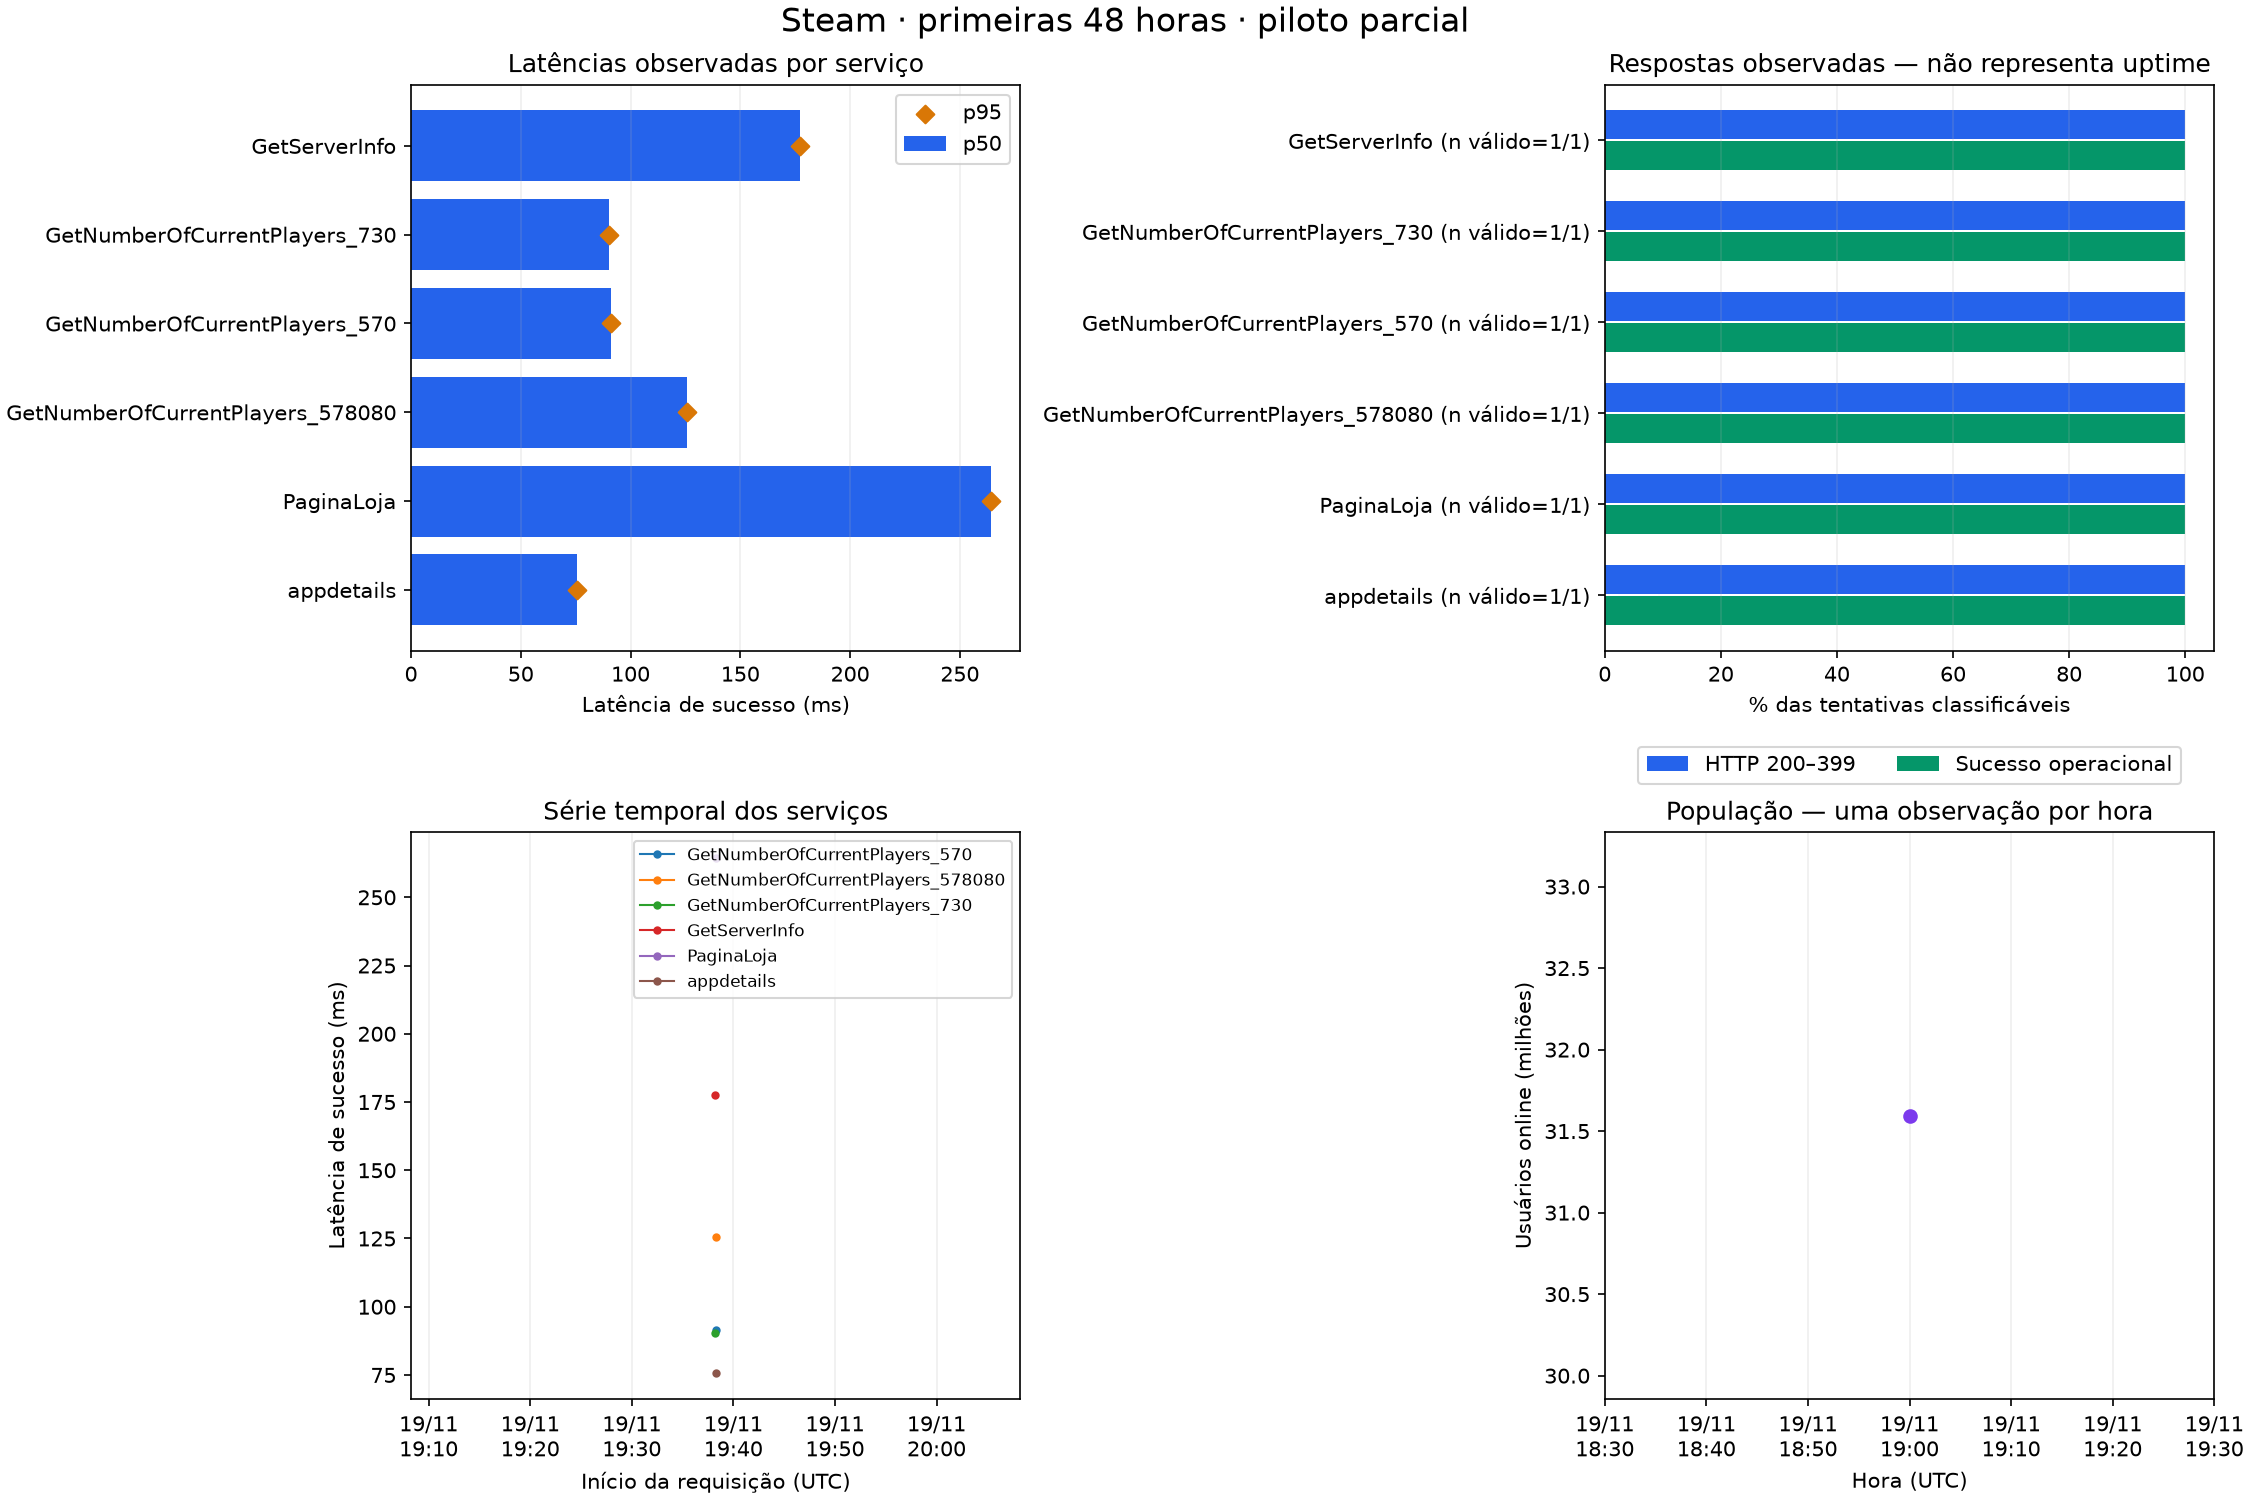

,hora_utc,timestamp_fonte,usuarios_online,jogadores_top,valores_usuarios_distintos_na_hora
0,2026-11-19 19:00:00+00:00,2026-11-19 19:38:11.983+00:00,31595637,1853036,1


In [4]:
display(Image(filename=str(arquivos['grafico'])))
usuarios = pd.read_csv(arquivos['usuarios_por_hora'])
display(usuarios)


## 4. Leitura e próximos passos do piloto

- Conferir no manifesto a duração observada, as horas com dados e o status do piloto. Com uma rodada, a análise é preliminar.
- Depois das primeiras 24–48 horas, executar novamente todas as células para atualizar este mesmo relatório.
- Conferir a dispersão e o comportamento por endpoint antes de revisar as premissas da simulação de poder. Registrar qualquer mudança ao protocolo.
- A Sprint 1 não estima os efeitos reais de H1, H2 e H3. Os testes dessas hipóteses dependem da coleta completa e do tratamento da dependência temporal.

O planejamento sintético de duração está em `analise/poder.py`; instruções e limites estão no [README](../README.md).